# 11 · Chronos-2 as an encoder: what the embeddings are good for

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/epjover/chronos2-in-practice/blob/main/notebooks/11_embeddings.ipynb)

Companion notebook for *Chronos-2 in Practice (7/7)*.

`Chronos2Pipeline.embed` returns what the encoder computed for a series before any forecast is
decoded. The library documents the call; what it is good for is left to the reader.
This notebook measures four uses, each against the same control: the raw window, standardised
the way the encoder standardises its input. An embedding earns its place only where it beats
the numbers it was made from.

**What you will learn**

- What `embed` returns and three ways to pool it into one vector per window.
- **What the embedding knows**: a linear probe for the weekday and the month.
- **Analog days**: retrieve the most similar days of the past and use what followed them as a
  forecast.
- **Series that behave alike**: a tree of the generation, load and price series.
- **Anomalies**: holidays on working days, and three injected defects, scored by the distance
  to the nearest ordinary windows.

Runtime: ~2 min on a GPU (FAST_MODE: ~2 min on a CPU, on one window in five).

In [1]:
# On Google Colab, clone the companion repo and install it (Colab's own PyTorch is kept).
# Locally, `uv sync` already installed everything and this cell does nothing.
import sys

if "google.colab" in sys.modules:
    !git clone --depth 1 https://github.com/epjover/chronos2-in-practice.git
    %cd chronos2-in-practice
    %pip install -q .
    import importlib

    importlib.invalidate_caches()

In [2]:
import time

import numpy as np
import pandas as pd
from huggingface_hub.utils import logging as hub_logging
from IPython.display import Image, display
from transformers.utils import logging as transformers_logging

from c2p.config import SEED, get_device, get_paths, is_fast_mode, set_seed
from c2p.data import add_calendar_features, spain_energy_frame, validate_and_prepare
from c2p.embeddings import (
    POOLS,
    analog_forecast,
    cosine_neighbors,
    embed_windows,
    knn_score,
    ridge_probe,
    roc_auc,
    sliding_windows,
    standardize_windows,
)
from c2p.experiments import FREQ, LOAD
from c2p.models import load_chronos2
from c2p.plots.embeddings import plot_analogs, plot_dendrogram
from c2p.plotting import plot_benchmarks, save_figure, set_style
from c2p.results import load_results, run_metadata, save_results
from c2p.schema import ID_COL, TIMESTAMP_COL

FAST_MODE = is_fast_mode(default=False)  # True: one day in five
PATHS = get_paths(fast_mode=FAST_MODE)
set_seed()
DEVICE = get_device()
set_style()
hub_logging.set_verbosity_error()
transformers_logging.disable_progress_bar()

for key, value in run_metadata(device=DEVICE, fast_mode=FAST_MODE).items():
    print(f"{key:>20}: {value}")

              python: 3.11.17
              device: cpu
           fast_mode: False
                seed: 42
          run_at_utc: 2026-11-25 23:06
                 cpu: 12th Gen Intel(R) Core(TM) i9-12900K
     cores_available: 8
       torch_threads: 8
                 gpu: none
 chronos-forecasting: 2.3.2
               torch: 2.14.1
              pandas: 3.1.0
               numpy: 2.4.6
                 fev: 0.10.0
       statsforecast: 2.0.1


## 1. One vector per window

The unit of this notebook is a **window**: the 192 hours (eight days, twelve patches of 16
steps) that end at a day-ahead cutoff, 22:00 UTC. There is one per day from 2015 to 2018. The
windows of 2015 to 2017 are the library, the ones the model may look things up in; the 365
windows of 2018 are the test set, the same days as the day-ahead backtest of the series.

`embed` returns, for each window, one vector of 768 numbers per patch, then the [REG] token
that closes the context, then the token of the first future patch. Three ways to make one
vector of that:

- `mean`: the average of the patch vectors;
- `reg`: the [REG] token;
- `forecast`: the future-patch token, the one the forecast head reads.

The encoder standardises each window first (it returns the location and scale separately), so
the level of the series is not in the embedding. The control is built the same way: the raw
window minus its mean, over its standard deviation.

In [3]:
WINDOW = 192
HORIZON = 24
raw = spain_energy_frame()
numeric = [column for column in raw.columns if column not in (ID_COL, TIMESTAMP_COL)]
frame, _ = validate_and_prepare(raw[[ID_COL, TIMESTAMP_COL, *numeric]], freq=FREQ, target=LOAD)
calendar = add_calendar_features(frame[[ID_COL, TIMESTAMP_COL]])
stamps = pd.DatetimeIndex(frame[TIMESTAMP_COL])
load = frame[LOAD].to_numpy("float64")

# One window per day, ending at the day-ahead cutoff, with 24 hours after it to compare with.
ends = np.flatnonzero(stamps.hour == 22) + 1
ends = ends[(ends >= WINDOW) & (ends + HORIZON <= len(load))]
ends = ends[:: 5 if FAST_MODE else 1]
cutoffs = stamps[ends - 1]
windows = sliding_windows(load, length=WINDOW, ends=ends)
futures = sliding_windows(load, length=HORIZON, ends=ends + HORIZON)
is_test = np.asarray(cutoffs >= pd.Timestamp("2017-12-31 22:00"))
is_library = np.asarray(cutoffs <= pd.Timestamp("2017-12-30 22:00"))
print(
    f"{len(windows):,} windows of {WINDOW} h: {is_library.sum():,} in the library "
    f"({cutoffs[is_library][0].date()} to {cutoffs[is_library][-1].date()}), "
    f"{is_test.sum()} in the test year"
)

pipeline = load_chronos2(device=DEVICE)
start = time.perf_counter()
REPRESENTATIONS = {"raw window": np.nan_to_num(standardize_windows(windows))}
for pool in POOLS:
    REPRESENTATIONS[f"embedding ({pool})"] = embed_windows(pipeline, windows, pool=pool)
    assert np.isfinite(REPRESENTATIONS[f"embedding ({pool})"]).all()
elapsed = time.perf_counter() - start
print(f"{len(POOLS)} poolings of {len(windows):,} windows in {elapsed:.1f} s")
for name, values in REPRESENTATIONS.items():
    print(f"  {name:<22} {values.shape}")


def interval(values: np.ndarray, n_resamples: int = 2000) -> tuple[float, float]:
    """95% bootstrap interval of the mean of ``values`` (one value per test window)."""
    rng = np.random.default_rng(SEED)
    draws = rng.integers(0, len(values), size=(n_resamples, len(values)))
    means = np.asarray(values, dtype="float64")[draws].mean(axis=1)
    return float(np.quantile(means, 0.025)), float(np.quantile(means, 0.975))

1,453 windows of 192 h: 1,088 in the library (2015-01-08 to 2017-12-30), 365 in the test year
3 poolings of 1,453 windows in 30.4 s
  raw window             (1453, 192)
  embedding (mean)       (1453, 768)
  embedding (reg)        (1453, 768)
  embedding (forecast)   (1453, 768)


## 2. What does the embedding know?

A **linear probe** asks whether a property can be read off a representation with a weighted sum
and nothing more. Two properties that matter for demand and that nobody told the model: the
weekday of the day about to be forecast, and the month. A ridge classifier is fitted on the
library windows and scored on 2018.

The raw window is a serious control here. Eight days of hourly load contain a weekend at a
position that gives the weekday away, so a linear model on the raw values should do well on
that task. The month is harder: the level is gone, so it has to be read from the shape of the
days.

Saved 11_probe_accuracy.csv


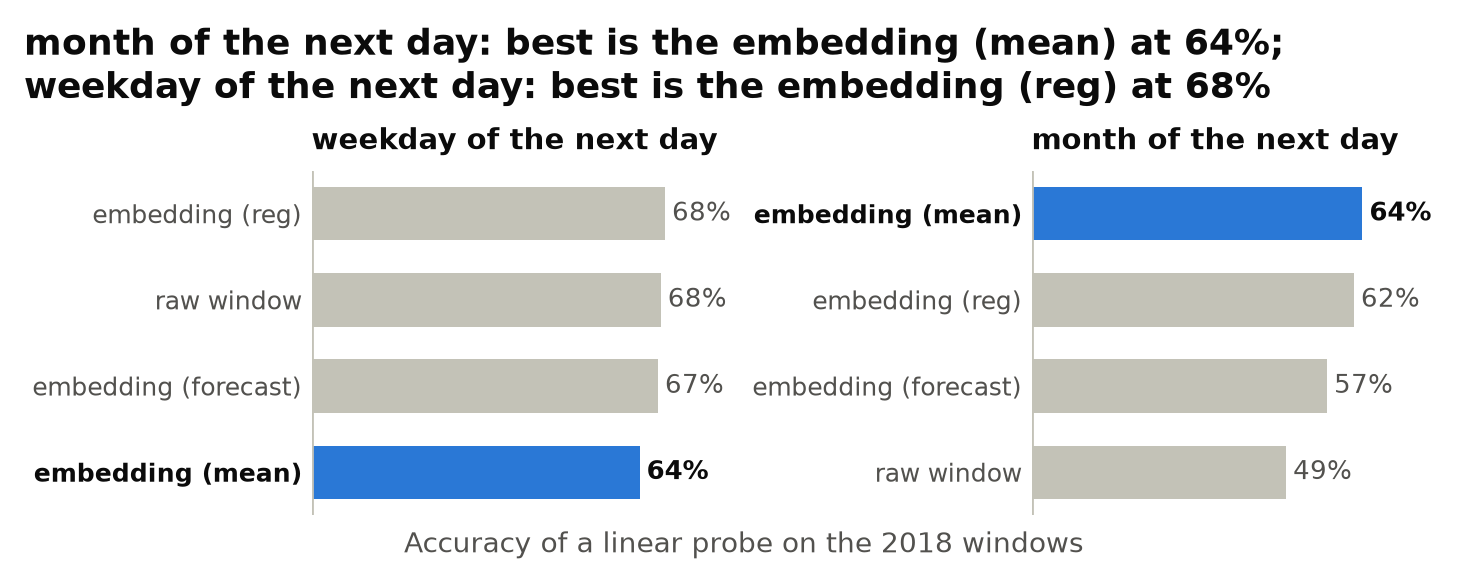

,task,representation,accuracy,ci_low,ci_high,majority_class,n_train,n_test
0,weekday of the next day,raw window,0.677,0.630,0.726,0.143,1088,365
1,weekday of the next day,embedding (mean),0.636,0.586,0.682,0.143,1088,365
2,weekday of the next day,embedding (reg),0.685,0.636,0.734,0.143,1088,365
3,weekday of the next day,embedding (forecast),0.671,0.622,0.718,0.143,1088,365
4,month of the next day,raw window,0.493,0.444,0.545,0.085,1088,365
5,month of the next day,embedding (mean),0.641,0.595,0.690,0.085,1088,365
6,month of the next day,embedding (reg),0.625,0.578,0.674,0.085,1088,365
7,month of the next day,embedding (forecast),0.573,0.523,0.625,0.085,1088,365


In [4]:
forecast_day = cutoffs + pd.Timedelta(hours=2)  # the local day the next 24 hours fall on
LABELS = {
    "weekday of the next day": np.asarray(forecast_day.day_of_week),
    "month of the next day": np.asarray(forecast_day.month),
}
rows = []
for task, labels in LABELS.items():
    counts = np.bincount(labels[is_library])
    for name, values in REPRESENTATIONS.items():
        predicted = ridge_probe(values[is_library], labels[is_library], values[is_test])
        correct = predicted == labels[is_test]
        low, high = interval(correct)
        rows.append(
            {
                "task": task,
                "representation": name,
                "accuracy": correct.mean(),
                "ci_low": low,
                "ci_high": high,
                "majority_class": counts.max() / counts.sum(),
                "n_train": int(is_library.sum()),
                "n_test": int(is_test.sum()),
            }
        )
print("Saved", save_results(pd.DataFrame(rows), "11_probe_accuracy", PATHS).name)

probes = load_results("11_probe_accuracy", PATHS)
best = probes.sort_values("accuracy").groupby("task").tail(1).set_index("task")
title = "; ".join(
    f"{task}: best is the {row['representation']} at {row['accuracy']:.0%}"
    for task, row in best.iterrows()
)
fig = plot_benchmarks(
    probes.rename(columns={"representation": "model", "task": "benchmark"}),
    value="accuracy",
    highlight="embedding (mean)",
    xlabel="Accuracy of a linear probe on the 2018 windows",
    title=title,
    value_format="{:.0%}",
    panel_width=3.6,
)
(figure_path,) = save_figure(fig, "11_probe_accuracy", PATHS.figures)
display(Image(filename=figure_path, width=800))
probes.round(3)

## 3. Analog days

The oldest forecasting method there is: find the days of the past that looked like today, and
see what followed them. `analog_forecast` takes each 2018 window, retrieves its five nearest
library windows by cosine similarity, expresses what followed each of them in units of its own
window, averages, and brings the result back to the level and scale of the query.

This is not a contender for the forecast: it gives a point and no interval. It is a test of the
embedding. If the nearest neighbours in embedding space are days that continue the same way,
their average will be a decent forecast, and better than the one built on neighbours in raw
space. The reference is yesterday repeated, the seasonal naive of notebook `02`.

In [5]:
K = 5
actual = futures[is_test]


def window_wape(forecast: np.ndarray) -> np.ndarray:
    """WAPE of each test window, as ``c2p.eval.evaluate`` computes it."""
    return np.nansum(np.abs(forecast - actual), axis=1) / np.nansum(np.abs(actual), axis=1)


forecasts = {"yesterday repeated": windows[is_test][:, -HORIZON:]}
for name, values in REPRESENTATIONS.items():
    forecasts[f"analogs: {name}"] = analog_forecast(
        values[is_test],
        values[is_library],
        query_windows=windows[is_test],
        library_windows=windows[is_library],
        library_futures=futures[is_library],
        k=K,
    )
rows = []
errors = {name: window_wape(forecast) for name, forecast in forecasts.items()}
for name, wape in errors.items():
    low, high = interval(wape)
    # Paired with the raw-window analogs, window by window.
    gap = wape - errors["analogs: raw window"]
    gap_low, gap_high = interval(gap)
    rows.append(
        {
            "forecast": name,
            "WAPE": wape.mean(),
            "ci_low": low,
            "ci_high": high,
            "vs_raw_window": gap.mean(),
            "vs_raw_ci_low": gap_low,
            "vs_raw_ci_high": gap_high,
            "n_windows": len(wape),
        }
    )
print("Saved", save_results(pd.DataFrame(rows), "11_analog_forecast", PATHS).name)
load_results("11_analog_forecast", PATHS).round(4)

Saved 11_analog_forecast.csv


,forecast,WAPE,ci_low,ci_high,vs_raw_window,vs_raw_ci_low,vs_raw_ci_high,n_windows
0,yesterday repeated,0.0885,0.0813,0.0960,0.0278,0.0212,0.0346,365
1,analogs: raw window,0.0607,0.0553,0.0661,0.0000,0.0000,0.0000,365
2,analogs: embedding (mean),0.0585,0.0535,0.0635,-0.0022,-0.0071,0.0024,365
3,analogs: embedding (reg),0.0564,0.0516,0.0616,-0.0042,-0.0085,-0.0000,365
4,analogs: embedding (forecast),0.0562,0.0510,0.0613,-0.0045,-0.0096,0.0006,365


Analogs of 2018-06-06 (Wednesday): ['2017-07-06', '2017-11-04', '2015-06-15', '2017-09-04', '2016-05-16']
Cosine similarity: [0.9374 0.9273 0.9247 0.924  0.9225]


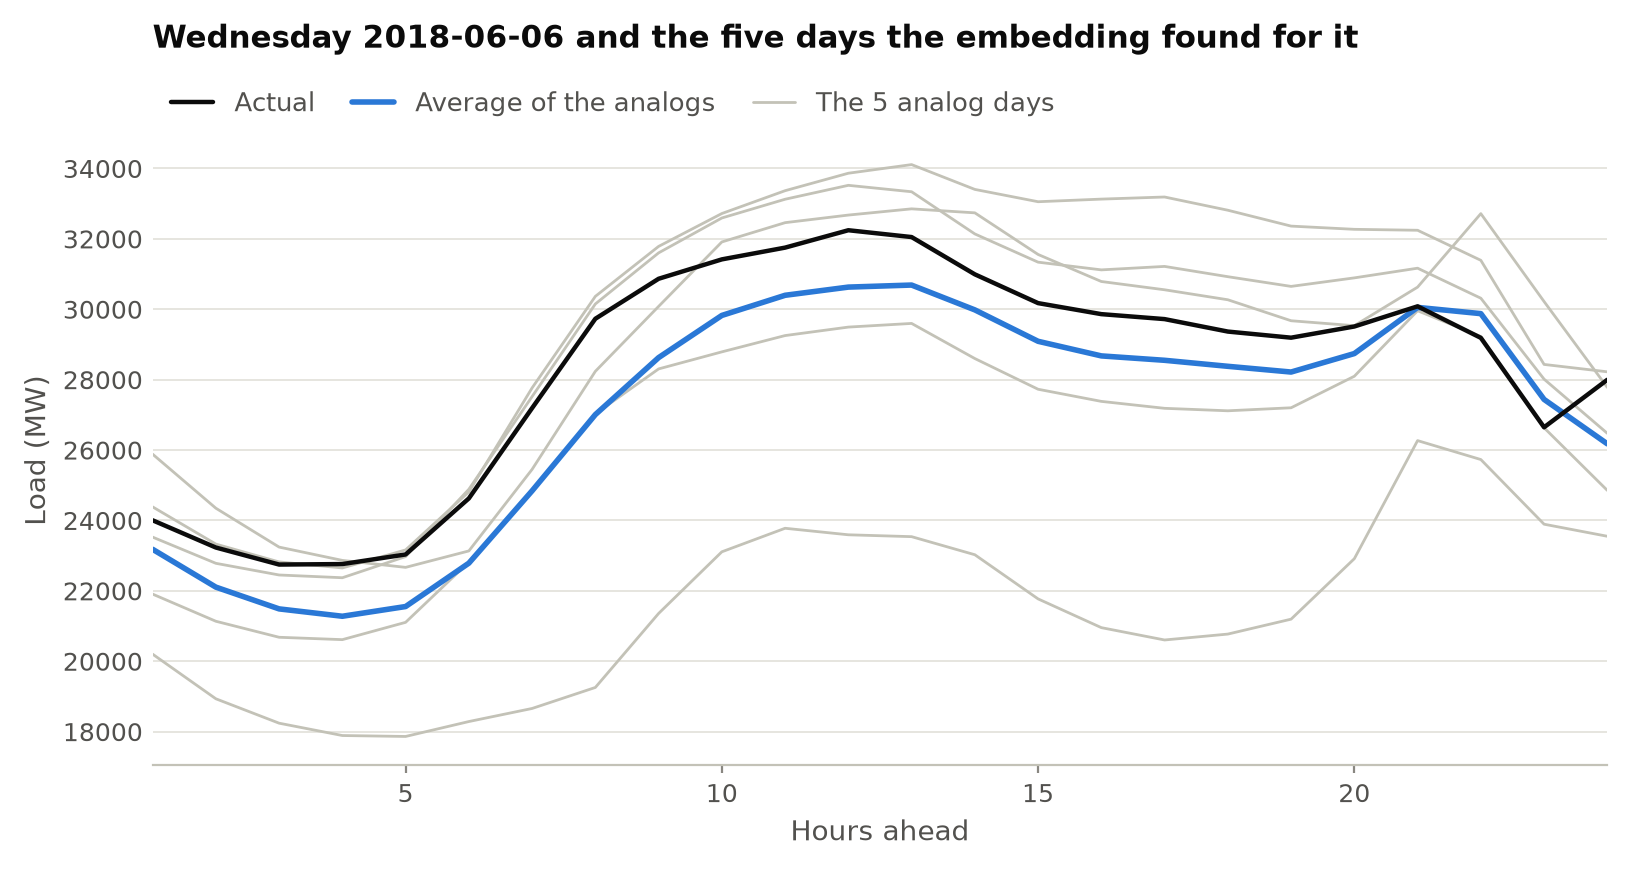

In [6]:
# One day, fixed in advance: the forecast of Wednesday 6 June 2018.
example = int(np.flatnonzero(np.asarray(cutoffs[is_test] >= pd.Timestamp("2018-06-05")))[0])
embedding = REPRESENTATIONS["embedding (mean)"]
indices, similarity = cosine_neighbors(embedding[is_test][[example]], embedding[is_library], k=K)
library_windows, library_futures = windows[is_library], futures[is_library]
query = windows[is_test][example]
analogs = np.stack(
    [
        np.nanmean(query)
        + np.nanstd(query)
        * (library_futures[i] - np.nanmean(library_windows[i]))
        / np.nanstd(library_windows[i])
        for i in indices[0]
    ]
)
day = cutoffs[is_test][example] + pd.Timedelta(hours=2)
found = [str(date.date()) for date in cutoffs[is_library][indices[0]] + pd.Timedelta(hours=2)]
print(f"Analogs of {day.date()} ({day.day_name()}): {found}")
print("Cosine similarity:", np.round(similarity[0], 4))
ax = plot_analogs(
    actual[example],
    analogs,
    forecasts["analogs: embedding (mean)"][example],
    title=f"{day.day_name()} {day.date()} and the five days the embedding found for it",
    ylabel="Load (MW)",
)
(figure_path,) = save_figure(ax.figure, "11_analog_days", PATHS.figures)
display(Image(filename=figure_path, width=800))

## 4. Series that behave alike

The same embedding works across series. Each of the dataset's hourly series (load, price, the
operator's forecasts and every generation technology) is embedded over the last 2,048 hours of
2017, and the tree below joins the ones whose embeddings point the same way. Six generation
series are constant (zero for the whole period) and are left out: a constant has no shape to
embed.

There is no score to report here, only a check against what is known about the system: a
forecast should sit next to the thing it forecasts, and technologies driven by the same
weather should sit together.

20 series embedded, 6 constant ones left out
Saved 11_series_neighbors.csv


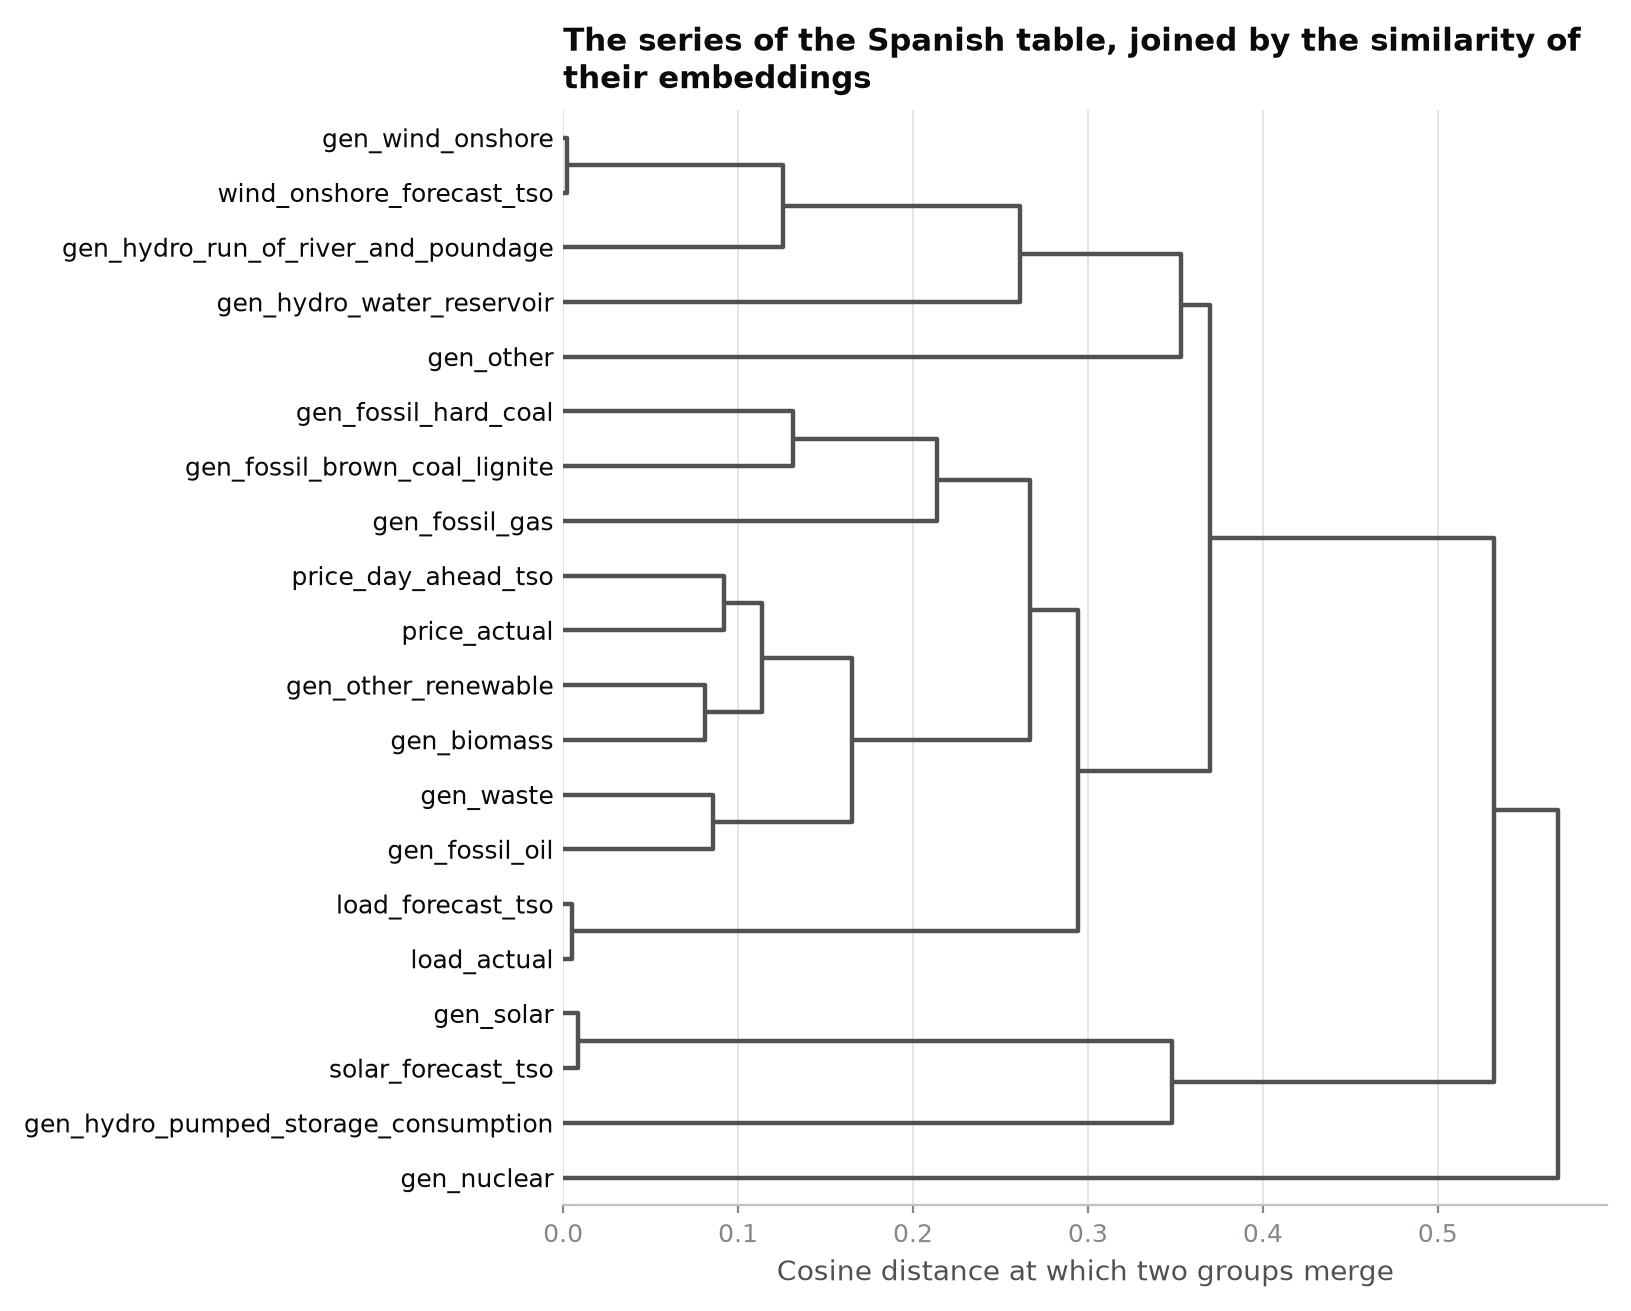

,series,nearest,cosine
19,gen_wind_onshore,wind_onshore_forecast_tso,0.9976
5,wind_onshore_forecast_tso,gen_wind_onshore,0.9976
0,load_actual,load_forecast_tso,0.9949
1,load_forecast_tso,load_actual,0.9949
17,gen_solar,solar_forecast_tso,0.9917
4,solar_forecast_tso,gen_solar,0.9917
6,gen_biomass,gen_other_renewable,0.9187
16,gen_other_renewable,gen_biomass,0.9187
18,gen_waste,gen_fossil_oil,0.9146
10,gen_fossil_oil,gen_waste,0.9146


In [7]:
CONTEXT = 2048
end = int(np.flatnonzero(stamps == pd.Timestamp("2017-12-31 22:00"))[0]) + 1
block = frame[numeric].to_numpy("float64")[end - CONTEXT : end]
varying = [i for i, column in enumerate(numeric) if np.nanstd(block[:, i]) > 0]
names = [numeric[i] for i in varying]
series_embeddings = embed_windows(pipeline, block[:, varying].T, pool="mean")
print(f"{len(names)} series embedded, {len(numeric) - len(names)} constant ones left out")

indices, similarity = cosine_neighbors(series_embeddings, series_embeddings, k=2)
neighbors = pd.DataFrame(
    {
        "series": names,
        "nearest": [names[i] for i in indices[:, 1]],  # column 0 is the series itself
        "cosine": similarity[:, 1],
    }
)
print("Saved", save_results(neighbors, "11_series_neighbors", PATHS).name)

ax = plot_dendrogram(
    series_embeddings,
    names,
    title="The series of the Spanish table, joined by the similarity of their embeddings",
)
(figure_path,) = save_figure(ax.figure, "11_series_tree", PATHS.figures)
display(Image(filename=figure_path, width=800))
load_results("11_series_neighbors", PATHS).sort_values("cosine", ascending=False).round(4)

## 5. Anomalies

An anomaly score needs no labels: `knn_score` is the mean cosine distance from a window to its
ten nearest ordinary windows. A window that resembles nothing seen before scores high. Whether
the score is any good does need labels, and there are two sources of them.

**Real ones.** A public holiday on a working day is a day that does not look like its weekday.
Each window is labelled by whether its last day was one, and scored against the ordinary
windows of the *other* years, so that a window is never compared with itself or with its
neighbours in time.

**Injected ones.** Three defects written into the last day of half of the 2018 windows, mild
enough that none is visible at a glance: one hour 30% too high, the last twelve hours frozen,
the last day 10% too high. The other half stays clean, and the library is 2015 to 2017.

The measure is the ROC AUC: the chance that a window with the defect scores above one without.
0.5 is a coin.

In [8]:
# One hour before the cutoff: 22:00 UTC is already the next local day in summer.
at_cutoff = calendar.iloc[ends - 2]
holiday = (at_cutoff["is_holiday"].to_numpy() == 1) & (at_cutoff["day_of_week"].to_numpy() < 5)
years = np.asarray(cutoffs.year)
print(f"{int(holiday.sum())} windows end on a public holiday that fell on a working day")

rows = []
for name, values in REPRESENTATIONS.items():
    scores = np.full(len(values), np.nan)
    for year in np.unique(years):
        queries = years == year
        ordinary = (years != year) & ~holiday
        scores[queries] = knn_score(values[queries], values[ordinary], k=10)
    rows.append(
        {
            "anomaly": "holiday on a working day",
            "representation": name,
            "auc": roc_auc(scores, holiday),
            "n_anomalies": int(holiday.sum()),
            "n_windows": len(scores),
        }
    )


def inject(clean: np.ndarray, kind: str, rng: np.random.Generator) -> np.ndarray:
    """Copy of the windows with one defect written into the last day of each."""
    out = clean.copy()
    if kind == "one hour 30% too high":
        hours = rng.integers(WINDOW - 24, WINDOW, size=len(out))
        out[np.arange(len(out)), hours] *= 1.3
    elif kind == "last 12 hours frozen":
        out[:, -12:] = out[:, [-13]]
    elif kind == "last day 10% too high":
        out[:, -24:] *= 1.1
    else:
        raise ValueError(kind)
    return out


rng = np.random.default_rng(SEED)
test_windows = windows[is_test]
corrupted = rng.random(len(test_windows)) < 0.5
for kind in ("one hour 30% too high", "last 12 hours frozen", "last day 10% too high"):
    mixed = np.where(corrupted[:, None], inject(test_windows, kind, rng), test_windows)
    candidates = {"raw window": np.nan_to_num(standardize_windows(mixed))}
    for pool in POOLS:
        candidates[f"embedding ({pool})"] = embed_windows(pipeline, mixed, pool=pool)
    for name, values in candidates.items():
        scores = knn_score(values, REPRESENTATIONS[name][is_library], k=10)
        rows.append(
            {
                "anomaly": kind,
                "representation": name,
                "auc": roc_auc(scores, corrupted),
                "n_anomalies": int(corrupted.sum()),
                "n_windows": len(scores),
            }
        )
print("Saved", save_results(pd.DataFrame(rows), "11_anomaly_auc", PATHS).name)

anomalies = load_results("11_anomaly_auc", PATHS)
anomalies.pivot_table(index="anomaly", columns="representation", values="auc", sort=False).round(3)

30 windows end on a public holiday that fell on a working day
Saved 11_anomaly_auc.csv


representation,raw window,embedding (mean),embedding (reg),embedding (forecast)
anomaly,,,,
holiday on a working day,0.671,0.723,0.772,0.752
one hour 30% too high,0.639,0.647,0.679,0.676
last 12 hours frozen,0.617,0.872,0.902,0.948
last day 10% too high,0.642,0.665,0.697,0.696


## Summary

In [9]:
probes = load_results("11_probe_accuracy", PATHS)
analog = load_results("11_analog_forecast", PATHS).set_index("forecast")
anomalies = load_results("11_anomaly_auc", PATHS)

print("Linear probe, accuracy on 2018 (the share of the largest class is the floor):")
for task, group in probes.groupby("task", sort=False):
    print(f"  {task} (largest class {group['majority_class'].iloc[0]:.0%})")
    for row in group.itertuples():
        print(
            f"    {row.representation:<22} {row.accuracy:6.1%} "
            f"[{row.ci_low:.1%}, {row.ci_high:.1%}]"
        )

print("\nAnalog forecast of the next 24 hours, WAPE on 2018:")
for name, row in analog.iterrows():
    versus = (
        ""
        if name in ("yesterday repeated", "analogs: raw window")
        else f"   vs raw-window analogs {row['vs_raw_window']:+.2%} "
        f"[{row['vs_raw_ci_low']:+.2%}, {row['vs_raw_ci_high']:+.2%}]"
    )
    print(f"  {name:<32} {row['WAPE']:6.2%} [{row['ci_low']:.2%}, {row['ci_high']:.2%}]{versus}")

print("\nAnomaly score, ROC AUC:")
table = anomalies.pivot_table(index="anomaly", columns="representation", values="auc", sort=False)
print(table.round(3).to_string())

Linear probe, accuracy on 2018 (the share of the largest class is the floor):
  weekday of the next day (largest class 14%)
    raw window              67.7% [63.0%, 72.6%]
    embedding (mean)        63.6% [58.6%, 68.2%]
    embedding (reg)         68.5% [63.6%, 73.4%]
    embedding (forecast)    67.1% [62.2%, 71.8%]
  month of the next day (largest class 9%)
    raw window              49.3% [44.4%, 54.5%]
    embedding (mean)        64.1% [59.5%, 69.0%]
    embedding (reg)         62.5% [57.8%, 67.4%]
    embedding (forecast)    57.3% [52.3%, 62.5%]

Analog forecast of the next 24 hours, WAPE on 2018:
  yesterday repeated                8.85% [8.13%, 9.60%]
  analogs: raw window               6.07% [5.53%, 6.61%]
  analogs: embedding (mean)         5.85% [5.35%, 6.35%]   vs raw-window analogs -0.22% [-0.71%, +0.24%]
  analogs: embedding (reg)          5.64% [5.16%, 6.16%]   vs raw-window analogs -0.42% [-0.85%, -0.00%]
  analogs: embedding (forecast)     5.62% [5.10%, 6.13%]   vs ra

**What to take from it.** The embedding is a general-purpose description of a window's shape,
free for anyone who already runs the model. Whether it beats a much simpler description is an
empirical question with a different answer for each use, and the tables above are the answer
for this series. Part 7 reads them.